# Session 20 Solutions: Logistic Regression and How Models Learn

Data Science with Python, Level 1, Stage 3: Statistics and ML Fundamentals

Try each exercise yourself before reading its solution. There is usually more than one correct answer; compare your approach with this one.

## Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression, SGDRegressor

sns.set_theme(style="whitegrid")
DATA_URL = "https://raw.githubusercontent.com/mohammadyahoo/ds-python-course/main/data/"
exams = pd.read_csv(DATA_URL + "exam_scores.csv")
x = exams["study_hours_week"].to_numpy()
y = exams["math"].to_numpy(dtype=float)
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix

churn = pd.read_csv(DATA_URL + "telecom_churn.csv")
churn["left"] = (churn["churn"] == "Yes").astype(int)

## In-Class Exercises

### In-Class Exercise 1: Plot the Descent

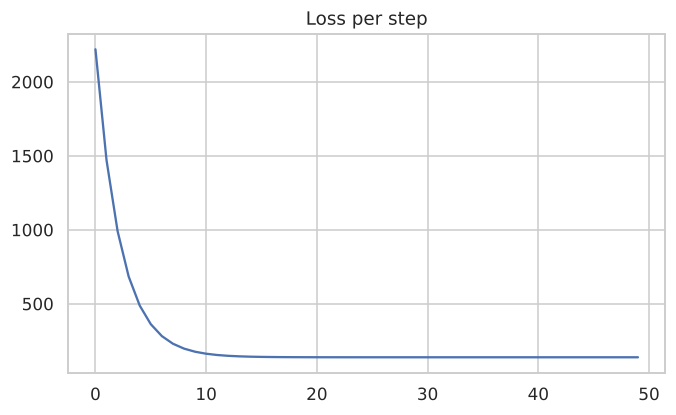

In [2]:
x_std = (x - x.mean()) / x.std()
w, b, losses = 0.0, 0.0, []
for _ in range(50):
    error = y - (w * x_std + b)
    w += 0.1 * 2 * np.mean(x_std * error)
    b += 0.1 * 2 * np.mean(error)
    losses.append(np.mean((y - (w * x_std + b)) ** 2))
plt.plot(losses)
plt.title("Loss per step")
plt.show()

### In-Class Exercise 2: Find the Breaking Point

In [3]:
x_std = (x - x.mean()) / x.std()
for lr in [0.5, 0.9, 1.0, 1.1]:
    w, b = 0.0, 0.0
    for _ in range(50):
        error = y - (w * x_std + b)
        w += lr * 2 * np.mean(x_std * error)
        b += lr * 2 * np.mean(error)
    print(lr, round(np.mean((y - (w * x_std + b)) ** 2), 1))

0.5 138.0
0.9 138.0
1.0 3391.6
1.1 269456888920.5


### In-Class Exercise 3: Risky Customers

In [4]:
churn["monthly_contract"] = (churn["contract"] == "Month-to-month").astype(int)
churn["fiber"] = (churn["internet"] == "Fiber").astype(int)
churn["echeck"] = (churn["payment_method"] == "Electronic check").astype(int)
features = ["tenure_months", "monthly_charges", "support_calls", "senior", "monthly_contract", "fiber", "echeck"]
X_train, X_test, y_train, y_test = train_test_split(churn[features].astype(float), churn["left"], test_size=0.25, random_state=42, stratify=churn["left"])
scaler = StandardScaler().fit(X_train)
m = LogisticRegression().fit(scaler.transform(X_train), y_train)
risk = pd.Series(m.predict_proba(scaler.transform(X_test))[:, 1], index=X_test.index)
churn.loc[risk.nlargest(10).index, ["contract", "tenure_months", "churn"]].assign(risk=risk.nlargest(10).round(2))

,contract,tenure_months,churn,risk
124,Month-to-month,5,Yes,0.83
971,Month-to-month,1,Yes,0.79
1773,Month-to-month,18,Yes,0.76
322,Month-to-month,10,Yes,0.75
706,Month-to-month,16,No,0.75
629,Month-to-month,11,Yes,0.75
466,Month-to-month,22,Yes,0.74
1654,Month-to-month,13,Yes,0.73
357,Month-to-month,12,Yes,0.73
59,Month-to-month,19,No,0.72


### In-Class Exercise 4: Choose a Threshold

In [5]:
churn["monthly_contract"] = (churn["contract"] == "Month-to-month").astype(int)
churn["fiber"] = (churn["internet"] == "Fiber").astype(int)
churn["echeck"] = (churn["payment_method"] == "Electronic check").astype(int)
features = ["tenure_months", "monthly_charges", "support_calls", "senior", "monthly_contract", "fiber", "echeck"]
X_train, X_test, y_train, y_test = train_test_split(churn[features].astype(float), churn["left"], test_size=0.25, random_state=42, stratify=churn["left"])
sc = StandardScaler().fit(X_train)
proba = LogisticRegression().fit(sc.transform(X_train), y_train).predict_proba(sc.transform(X_test))[:, 1]
for t in np.arange(0.1, 1.0, 0.1):
    tn, fp, fn, tp = confusion_matrix(y_test, (proba >= t).astype(int)).ravel()
    print(round(t, 1), fn * 300 + fp * 40)

0.1 10120
0.2 10360
0.3 11600
0.4 19260
0.5 29540
0.6 34920
0.7 42240
0.8 45000
0.9 45300


## Part A: Basic

### Exercise 1: Compute a Loss

In [6]:
def mae(w, b):
    return np.mean(np.abs(y - (w * x + b)))

print(round(mae(1.5, 46), 2), round(mae(0, 57), 2))

9.26 10.41


### Exercise 2: Churn by Contract

In [7]:
churn["monthly_contract"] = (churn["contract"] == "Month-to-month").astype(int)
m = LogisticRegression().fit(churn[["monthly_contract"]], churn["left"])
print(m.predict_proba(pd.DataFrame({"monthly_contract": [0, 1]}))[:, 1].round(3))
print(churn.groupby("monthly_contract")["left"].mean().round(3))

[0.12 0.45]
monthly_contract
0    0.118
1    0.451
Name: left, dtype: float64


## Part B: Intermediate

### Exercise 3: Gradient Descent for Rentals

Converting back: the slope divides by the std, and the intercept shifts by the slope times the mean.

In [8]:
bikes = pd.read_csv(DATA_URL + "bike_rentals.csv")
t = bikes["temp_c"].to_numpy()
r = bikes["rentals"].to_numpy(dtype=float)
ts = (t - t.mean()) / t.std()
w, b = 0.0, 0.0
for _ in range(300):
    error = r - (w * ts + b)
    w += 0.1 * 2 * np.mean(ts * error)
    b += 0.1 * 2 * np.mean(error)
slope = w / t.std()
intercept = b - slope * t.mean()
print(round(slope, 2), round(intercept, 1))
sk = LinearRegression().fit(t.reshape(-1, 1), r)
print(round(sk.coef_[0], 2), round(sk.intercept_, 1))

152.22 1724.9
152.22 1724.9


### Exercise 4: Fraud Detection Model

In [9]:
tx = pd.read_csv(DATA_URL + "card_transactions.csv")
cols = ["amount", "hour", "distance_from_home_km", "online", "new_merchant"]
X_train, X_test, y_train, y_test = train_test_split(tx[cols].astype(float), tx["is_fraud"], test_size=0.25, random_state=1, stratify=tx["is_fraud"])
sc = StandardScaler().fit(X_train)
m = LogisticRegression().fit(sc.transform(X_train), y_train)
pred = m.predict(sc.transform(X_test))
print(round(accuracy_score(y_test, pred), 4), round(1 - y_test.mean(), 4))
print(confusion_matrix(y_test, pred))
# Only 2 percent of payments are fraud, so predicting no fraud for everything already scores 98 percent.

0.998 0.982
[[1471    2]
 [   1   26]]


### Exercise 5: Probability Histogram

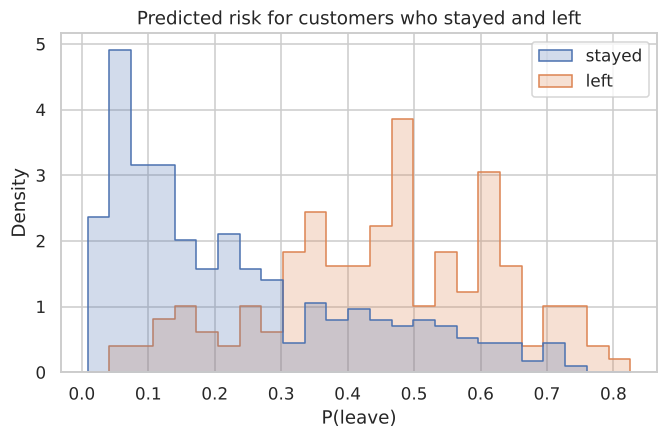

In [10]:
churn["monthly_contract"] = (churn["contract"] == "Month-to-month").astype(int)
churn["fiber"] = (churn["internet"] == "Fiber").astype(int)
churn["echeck"] = (churn["payment_method"] == "Electronic check").astype(int)
features = ["tenure_months", "monthly_charges", "support_calls", "senior", "monthly_contract", "fiber", "echeck"]
X_train, X_test, y_train, y_test = train_test_split(churn[features].astype(float), churn["left"], test_size=0.25, random_state=42, stratify=churn["left"])
sc = StandardScaler().fit(X_train)
proba = LogisticRegression().fit(sc.transform(X_train), y_train).predict_proba(sc.transform(X_test))[:, 1]
sns.histplot(x=proba, hue=y_test.map({0: "stayed", 1: "left"}).values, bins=25, element="step", stat="density", common_norm=False)
plt.title("Predicted risk for customers who stayed and left")
plt.xlabel("P(leave)")
plt.show()

## Part C: Challenge

### Exercise 6: Logistic Regression from Scratch

`C=1e6` switches off scikit-learn's default regularisation, which shrinks the weights slightly, so the two answers can be compared fairly.

In [11]:
churn["monthly_contract"] = (churn["contract"] == "Month-to-month").astype(int)
churn["fiber"] = (churn["internet"] == "Fiber").astype(int)
churn["echeck"] = (churn["payment_method"] == "Electronic check").astype(int)
features = ["tenure_months", "monthly_charges", "support_calls", "senior", "monthly_contract", "fiber", "echeck"]
X = churn[features].to_numpy(dtype=float)
Xs = (X - X.mean(axis=0)) / X.std(axis=0)
yy = churn["left"].to_numpy()
w, b = np.zeros(Xs.shape[1]), 0.0
for _ in range(2000):
    p = 1 / (1 + np.exp(-(Xs @ w + b)))
    w -= 0.1 * Xs.T @ (p - yy) / len(yy)
    b -= 0.1 * np.mean(p - yy)
print(w.round(3))
print(LogisticRegression(C=1e6).fit(Xs, yy).coef_[0].round(3))

[-0.525  0.367  0.347  0.125  0.743  0.196  0.293]
[-0.525  0.367  0.348  0.125  0.743  0.196  0.293]


## Part D: Cumulative Project: Apartment Prices

### Exercise 7: Apartment Prices: Expensive or Not?

In [12]:
flats = pd.read_csv(DATA_URL + "apartments.csv")
flats["expensive"] = (flats["price_k"] > flats["price_k"].median()).astype(int)
cols = ["area_m2", "rooms", "building_age", "distance_center_km", "elevator", "parking"]
X_train, X_test, y_train, y_test = train_test_split(flats[cols].astype(float), flats["expensive"], test_size=0.25, random_state=42, stratify=flats["expensive"])
sc = StandardScaler().fit(X_train)
m = LogisticRegression().fit(sc.transform(X_train), y_train)
pred = m.predict(sc.transform(X_test))
print(round(accuracy_score(y_test, pred), 3), round(max(y_test.mean(), 1 - y_test.mean()), 3))
print(confusion_matrix(y_test, pred))
print(pd.Series(np.exp(m.coef_[0]), index=cols).sort_values(ascending=False).round(2))

0.93 0.5
[[87 13]
 [ 1 99]]
area_m2               23.65
parking                1.83
elevator               1.59
rooms                  1.56
building_age           0.36
distance_center_km     0.05
dtype: float64


## Part E: Quiz Answers

| Question | Answer | Explanation |
| --- | --- | --- |
| 1 | B | Training tries to make the loss as small as possible. |
| 2 | B | Steps overshoot the minimum and the loss diverges. |
| 3 | B | Spam or not spam is a category. |
| 4 | B | It maps the weighted sum to a probability. |
| 5 | B | More cases cross the lower threshold. |